# Propose, review, apply: let a model find the boxes your dataset is missing

Labelled datasets are almost never complete: somebody forgot a box, or a class was added later. DataCopilot can ask a **real
open-vocabulary detection model** (Grounding DINO, Apache-2.0) to look for the classes of your dataset in every photo and write
down the boxes it thinks are missing as a **proposal**. A proposal is only a suggestion: nothing is changed until a person has
reviewed it, and accepting writes a *new* version of the dataset; the old one is never edited.

How we measure it honestly: we take the real COCO128 photos and **delete about one box in five** (a seeded, repeatable choice).
Those deleted boxes are the answer key. The model never sees them. Then we run the whole flow with the real model: propose,
review (we play the reviewer and accept exactly the proposals that match a deleted box), apply, and count what happened.

**Two things make this test friendlier than real life, so read the recall as optimistic.** First, our reviewer is an *oracle*: it knows the answer key, so it never accepts a wrong box and never rejects a right one; a human is slower and makes mistakes. Second, boxes deleted at random are not how real omissions look: real datasets miss the small, blurry, crowded and unusual objects that are also the hardest for the model, so the model will do worse on real omissions than on randomly deleted boxes.

Every number below was produced by actually running the commands: nothing is made up or hand-edited. The first run downloads
about 7 MB of photos and about 690 MB of model weights (a few minutes on a CPU for the model run itself). Run the cells from top to bottom.

**About the data and its licence.** The photos come from COCO (train2017) through the COCO128 sample published by Ultralytics. The
COCO annotations are licensed CC BY 4.0, and each image keeps the licence of its original Flickr owner. The notebook downloads the sample at
run time into a cache folder outside the repository and never copies, commits or redistributes any image.

**One honest caveat up front.** COCO128 is not labelled exhaustively: some real objects have no box at all. A proposal that is
correct but was never labelled in COCO counts as a *mistake* in our score, because the answer key does not contain it. The precision
below therefore *may* understate how often the model is right. We did not check how many of the wrong proposals are real unlabelled objects; the notebook only looks at a few.

### Set-up

The next cell prepares a clean work folder and the helper `datacopilot(...)`, which runs a real DataCopilot command exactly as a terminal
would and prints the command, its output and its **exit code** (0 means success).

In [ ]:
import hashlib
import json
import os
import shlex
import shutil
import subprocess
import sys
import tempfile
import time
import types
import urllib.request
import warnings
import zipfile
from pathlib import Path

# Where downloads are cached (outside the repository) and where this notebook works.
DATA = Path(
    os.environ.get("DATACOPILOT_NOTEBOOK_DATA")
    or Path(tempfile.gettempdir()) / "datacopilot-notebooks"
).resolve()
WORK = DATA / "work-propose"
shutil.rmtree(WORK, ignore_errors=True)  # start clean, so the notebook can be re-run from the top
WORK.mkdir(parents=True)
os.chdir(WORK)  # everything below uses paths relative to this folder

# Printing helper: hide the folders of this machine behind short placeholders.
_HIDE = [
    (str(p), name)
    for p, name in [
        (WORK, "<work>"),
        (WORK.resolve(), "<work>"),
        (DATA, "<data>"),
        (DATA.resolve(), "<data>"),
        (Path(tempfile.gettempdir()), "<tmp>"),
        (Path(tempfile.gettempdir()).resolve(), "<tmp>"),
        (Path.home(), "~"),
    ]
]
_HIDE.sort(key=lambda pair: -len(pair[0]))


def tidy(text):
    for real, placeholder in _HIDE:
        text = text.replace(real, placeholder)
    return text


class Done(types.SimpleNamespace):
    """What a command returned (shows nothing when it ends a cell)."""

    def _ipython_display_(self):
        pass


def datacopilot(*args, env=None, timed=False):
    """Run one `datacopilot` command like a terminal: show the command, what it prints and its exit code."""
    start = time.perf_counter()
    done = subprocess.run(  # noqa: S603  (our own command, no shell)
        [sys.executable, "-m", "datacopilot", *map(str, args)],
        capture_output=True,
        text=True,
        timeout=3600,
        env={**os.environ, "TQDM_DISABLE": "1", "HF_HUB_DISABLE_PROGRESS_BARS": "1", **(env or {})},
    )
    seconds = time.perf_counter() - start
    done.messages = [
        tidy(line) for line in done.stderr.splitlines() if line.strip() and not line.startswith("{")
    ]
    print("$ datacopilot " + " ".join(shlex.quote(str(a)) for a in args))
    for line in done.stdout.splitlines():
        print(tidy(line)[:240])
    for line in done.messages:
        print("[message]", line[:400])
    print(f"[exit code {done.returncode}" + (f", {seconds:.1f} s]" if timed else "]"))
    return Done(
        returncode=done.returncode,
        stdout=done.stdout,
        stderr=done.stderr,
        messages=done.messages,
        seconds=seconds,
    )


def latest_report(name="report.json"):
    """The report the last audit wrote next to us (JSON version)."""
    return json.loads(Path(name).read_text())


os.environ["DATACOPILOT_LOG_LEVEL"] = "ERROR"  # keep the technical JSON log lines out of this page
os.environ["TQDM_DISABLE"] = os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = (
    "1"  # no progress bars on this page
)
warnings.filterwarnings("ignore")
print("cache folder :", tidy(str(DATA)))
print("work folder  :", tidy(str(WORK)))
print("python       :", sys.version.split()[0])

cache folder : <data>
work folder  : <work>
python       : 3.13.9


**What this shows.** Every file this notebook creates lives in the work folder, and every path printed is relative to it; real folder names are hidden behind `<work>`, `<data>` and `~`.

## 1. Check the installation

The proposal model needs the optional `vlm` extra (`pip install "datacopilot[vlm]"`). `doctor` says whether it is available.

In [ ]:
datacopilot("doctor")

$ datacopilot doctor
ok
package: datacopilot 0.1.0 (dcp schema 1)
python: 3.13.9 on Darwin
dependencies: ok (click 8.5.0, jinja2 3.1.6, numpy 2.5.4, pyarrow 26.0.0, pydantic 2.14.1, structlog 26.1.0, typer 0.27.3)
extras: embed missing faiss-cpu; vlm available
settings: ok (env=prod, log_level=ERROR, workers=12, hash_cache=true, ci=false, cache_key=unset)
cache: ~/.cache/datacopilot (writable, 2 files, 22852 bytes)
faiss: not installed
gpu: tensor library 2.14.1, mps
plugins: formats=6, checks=7, embedders=4
[exit code 0]


**What this shows.** The `extras:` line lists `vlm available`, so the model libraries are installed. Nothing is downloaded by `doctor`.

## 2. The model, its licence and its pins

DataCopilot refuses to load a model whose licence is not on your allow-list, and it checks the model files against checksums that were written down
in advance, so you never get "whatever the website serves today". The registry card shows both.

In [ ]:
from datacopilot.models.registry import get_model

card = get_model(
    "grounding_dino", {"Apache-2.0", "MIT", "BSD-3-Clause"}
)  # raises if the licence is not allowed
print("model     :", card.model_id, "=", card.repo)
print("licence   :", card.license, "(checked before anything is downloaded)")
print("revision  :", card.revision, "(one exact commit, never a moving branch)")
print(
    "weights   :",
    {k: v[:16] + "..." for k, v in card.weights_sha256.items()},
    f"{sum(card.weights_bytes.values()) / 1e6:.0f} MB, safetensors only",
)
print("other files pinned too:", sorted(card.aux_sha256))

model     : grounding_dino = IDEA-Research/grounding-dino-tiny
licence   : Apache-2.0 (checked before anything is downloaded)
revision  : a2bb814dd30d776dcf7e30523b00659f4f141c71 (one exact commit, never a moving branch)
weights   : {'model.safetensors': '1a2412ef99bd74bc...'} 689 MB, safetensors only
other files pinned too: ['added_tokens.json', 'preprocessor_config.json', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']


**What this shows.** The model is Grounding DINO (tiny), Apache-2.0, pinned to one commit. Its weights are a `.safetensors` file, which holds only numbers and cannot run code, and
every file is compared with its checksum *before* it is loaded. No remote code is ever executed.

## 3. The real photos

Same download and safe-unpacking cells as in the first notebook: the file must match the pinned SHA-256 or it is deleted and the notebook stops, and every archive entry is checked before anything is written.

In [ ]:
# Pinned fingerprint of the one file we download (see the note above this cell for where it came from).
COCO128_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"
COCO128_SHA256 = "61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e"
COCO128_BYTES = 6_983_030
MAX_DOWNLOAD_BYTES = 50_000_000  # refuse anything bigger than this, whatever the server says
MAX_FILES, MAX_UNPACKED_BYTES, MAX_RATIO = 1_000, 100_000_000, 20


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def fetch_coco128():
    """Download COCO128 (HTTPS only, bounded, atomic); return its path once the pinned checksum matches."""
    if not COCO128_URL.startswith("https://"):
        raise RuntimeError("downloads must use HTTPS")
    DATA.mkdir(parents=True, exist_ok=True)
    target = DATA / "coco128.zip"
    if target.exists() and sha256_of(target) != COCO128_SHA256:
        target.unlink()  # never reuse a cached file whose checksum is wrong
    if not target.exists():
        partial = target.with_suffix(".part")
        try:
            with (
                urllib.request.urlopen(COCO128_URL, timeout=60) as reply,
                open(partial, "wb") as out,
            ):  # noqa: S310
                if int(reply.headers.get("Content-Length") or 0) > MAX_DOWNLOAD_BYTES:
                    raise RuntimeError("the server announced a file that is too big")
                received = 0
                for block in iter(lambda: reply.read(1 << 20), b""):
                    received += len(block)
                    if received > MAX_DOWNLOAD_BYTES:
                        raise RuntimeError("download is larger than the allowed maximum")
                    out.write(block)
        except OSError as problem:
            partial.unlink(missing_ok=True)
            raise RuntimeError(
                "Could not download COCO128 (" + type(problem).__name__ + "). "
                "These notebooks need the network once to fetch about 7 MB from "
                + COCO128_URL
                + ". "
                "Connect and run this cell again, or download that file yourself and save it as "
                "'coco128.zip' in the cache folder (set DATACOPILOT_NOTEBOOK_DATA to choose where it is)."
            ) from None
        except RuntimeError:
            partial.unlink(missing_ok=True)
            raise
        actual = sha256_of(partial)
        if actual != COCO128_SHA256:
            partial.unlink()
            raise RuntimeError(
                "COCO128 checksum mismatch (got "
                + actual
                + "); the file was deleted and nothing was unpacked"
            )
        partial.replace(target)  # atomic: a half-written file never carries the final name
    return target


def unpack_safely(archive_path, destination):
    """Unpack a zip we do not trust: check every entry first, then write into a fresh folder."""
    destination = Path(destination)
    if destination.exists():
        raise RuntimeError("the destination must be a fresh folder")
    with zipfile.ZipFile(archive_path) as archive:
        members = archive.infolist()
        if len(members) > MAX_FILES or sum(m.file_size for m in members) > MAX_UNPACKED_BYTES:
            raise RuntimeError("archive has too many files or unpacks to too much data")
        for member in members:
            name = member.filename
            is_link = ((member.external_attr >> 16) & 0o170000) == 0o120000
            if (
                name.startswith(("/", chr(92)))
                or ".." in Path(name).parts
                or ":" in name
                or is_link
            ):
                raise RuntimeError("unsafe entry in the archive: " + name)
            if member.compress_size and member.file_size / member.compress_size > MAX_RATIO:
                raise RuntimeError("suspiciously high compression ratio for " + name)
        for member in members:  # every entry passed; now write them one by one
            path = destination / member.filename
            if member.is_dir():
                path.mkdir(parents=True, exist_ok=True)
                continue
            path.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as source_file, open(path, "wb") as out:
                shutil.copyfileobj(source_file, out)
    return destination


zip_path = fetch_coco128()
print("file    :", zip_path.name, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
print("sha256  :", sha256_of(zip_path))
print(
    "checksum matches the pinned value: True (a mismatch stops the notebook before anything is unpacked)"
)

raw = unpack_safely(zip_path, "raw")
print("images  :", len(list((raw / "coco128/images/train2017").glob("*.jpg"))))
print("labels  :", len(list((raw / "coco128/labels/train2017").glob("*.txt"))))

file    : coco128.zip (7.0 MB)
sha256  : 61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e
checksum matches the pinned value: True (a mismatch stops the notebook before anything is unpacked)
images  : 128
labels  : 128


**What this shows.** The download matched the pinned checksum before anything was unpacked: 128 photos with 128 label files.

COCO128 has no list of class names and no validation set, so (as in the first notebook) we add the 80 official COCO class names and make every fifth photo the `val` split.

In [ ]:
# COCO128 is one folder of 128 photos with no list of class names and no validation split, so we
# add both: the 80 official COCO class names, and every fifth photo (sorted by name) becomes "val".
NAMES = [
    n.replace("_", " ")
    for n in "person bicycle car motorcycle airplane bus train truck boat traffic_light fire_hydrant stop_sign parking_meter bench bird cat dog horse sheep cow elephant bear zebra giraffe backpack umbrella handbag tie suitcase frisbee skis snowboard sports_ball kite baseball_bat baseball_glove skateboard surfboard tennis_racket bottle wine_glass cup fork knife spoon bowl banana apple sandwich orange broccoli carrot hot_dog pizza donut cake chair couch potted_plant bed dining_table toilet tv laptop mouse remote keyboard cell_phone microwave oven toaster sink refrigerator book clock vase scissors teddy_bear hair_drier toothbrush".split()
]
if len(NAMES) != 80:
    raise ValueError("expected the 80 COCO class names")


def build_yolo_layout(target="coco128"):
    """Copy the raw COCO128 files into the folder layout DataCopilot's YOLO reader expects."""
    target = Path(target)
    source = raw / "coco128"
    photos = sorted((source / "images/train2017").glob("*.jpg"))
    for number, photo in enumerate(photos):
        split = "val" if number % 5 == 4 else "train"
        (target / "images" / split).mkdir(parents=True, exist_ok=True)
        (target / "labels" / split).mkdir(parents=True, exist_ok=True)
        shutil.copy(photo, target / "images" / split / photo.name)
        label = source / "labels/train2017" / (photo.stem + ".txt")
        if label.exists():
            shutil.copy(label, target / "labels" / split / label.name)
    names = ", ".join(json.dumps(n) for n in NAMES)
    (target / "data.yaml").write_text(
        f"path: .\ntrain: images/train\nval: images/val\nnc: 80\nnames: [{names}]\n"
    )
    return target


build_yolo_layout("coco128")
print(sorted(p.name for p in Path("coco128").iterdir()))
print("train photos:", len(list(Path("coco128/images/train").glob("*.jpg"))))
print("val photos  :", len(list(Path("coco128/images/val").glob("*.jpg"))))

['data.yaml', 'images', 'labels']
train photos: 103
val photos  : 25


**What this shows.** The dataset now has the layout `images/<split>/` and `labels/<split>/` plus a `data.yaml`: the numbers of photos for training and validation are printed above.

## 4. The complete dataset, and the answer key

First the complete dataset as the COCO authors drew it. Then we copy it and **delete a seeded 20 percent of the boxes** from the copy. The deleted boxes are remembered here in the notebook, and only here.

In [ ]:
import random
import re
from collections import Counter

import matplotlib.pyplot as plt
from PIL import Image as PILImage

import datacopilot as dc
from datacopilot.core.geometry import cxcywh_norm_to_xyxy

plt.rcParams["figure.dpi"] = 55
datacopilot("ingest", "coco128", "--format", "yolo", "-o", "coco128.dcp")
full = dc.load("coco128.dcp")
size_of = {Path(i.file_path).name: (i.width, i.height) for i in full.images}
id_of = {Path(i.file_path).name: i.image_id for i in full.images}
file_of = {i.image_id: Path(i.file_path).name for i in full.images}
class_name = {c.id: c.name for c in full.categories}

HOLDOUT_FRACTION, HOLDOUT_SEED = 0.2, 20260101
shutil.copytree("coco128", "coco128_holdout")
rng = random.Random(HOLDOUT_SEED)  # noqa: S311  (a repeatable choice, not security)
held = []  # the answer key: (image id, class id, box in pixels)
for label_file in sorted(Path("coco128_holdout/labels").glob("*/*.txt")):
    name = label_file.stem + ".jpg"
    width, height = size_of[name]
    keep = []
    for line in label_file.read_text().splitlines():
        if not line.strip():
            continue
        cls, cx, cy, bw, bh = line.split()
        if rng.random() < HOLDOUT_FRACTION:
            held.append(
                (
                    id_of[name],
                    int(cls),
                    cxcywh_norm_to_xyxy(
                        (float(cx), float(cy), float(bw), float(bh)), width, height
                    ),
                )
            )
        else:
            keep.append(line)
    label_file.write_text("\n".join(keep) + ("\n" if keep else ""))

datacopilot("ingest", "coco128_holdout", "--format", "yolo", "-o", "holdout.dcp")
holdout = dc.load("holdout.dcp")
held_by = {}
for image_id, cls, box in held:
    held_by.setdefault((image_id, cls), []).append(box)
print("complete dataset :", len(full.annotations), "boxes in", len(full.images), "photos")
print(
    f"deleted (held out): {len(held)} boxes = {100 * len(held) / len(full.annotations):.1f} percent (seed {HOLDOUT_SEED})"
)
print(
    "dataset the model works on:",
    len(holdout.annotations),
    "boxes; photos that lost at least one box:",
    len({h[0] for h in held}),
)

$ datacopilot ingest coco128 --format yolo -o coco128.dcp
d9105ffb854e7dbeccf255a4848bd692
[exit code 0]


$ datacopilot ingest coco128_holdout --format yolo -o holdout.dcp
92573e6e3c31e6a9b80a399411e90826
[exit code 0]
complete dataset : 929 boxes in 128 photos
deleted (held out): 178 boxes = 19.2 percent (seed 20260101)
dataset the model works on: 751 boxes; photos that lost at least one box: 81


**What this shows.** The copy named `holdout.dcp` is COCO128 with about one box in five missing. The model will be asked to find boxes in it; the deleted boxes are the key to grade the answer.

## 5. What the audit says about each version

We run the ordinary audit on the complete dataset and on the one with holes, so that later we can see whether recovering boxes changes the picture.

In [ ]:
Path("reports").mkdir(exist_ok=True)


def audit_counts(name, path):
    datacopilot(
        "audit", path, "--no-hash-cache", "--fail-on", "none", "--report", f"reports/{name}.html"
    )
    report = json.loads(Path(f"reports/{name}.json").read_text())
    return Counter(
        (f["check"], f["payload"]["rule"], f["severity"]) for f in report["findings"]
    ), report["counts"]


audit_full, totals_full = audit_counts("complete", "coco128.dcp")
audit_hole, totals_hole = audit_counts("holdout", "holdout.dcp")


def show_findings(**columns):
    rows = sorted(set().union(*columns.values()))
    print(f"{'check':<11}{'what was found':<25}{'level':<6}" + "".join(f"{n:>10}" for n in columns))
    for row in rows:
        print(
            f"{row[0]:<11}{row[1]:<25}{row[2]:<6}"
            + "".join(f"{c[row]:>10}" for c in columns.values())
        )
    print(f"{'totals':<42}" + "".join(f"{sum(c.values()):>10}" for c in columns.values()))


show_findings(complete=audit_full, holdout=audit_hole)

$ datacopilot audit coco128.dcp --no-hash-cache --fail-on none --report reports/complete.html
passed critical=0 warn=12 info=1 run_id=44eaca2a-6a9a-4cf2-a49e-21d22c58cf77
[exit code 0]


$ datacopilot audit holdout.dcp --no-hash-cache --fail-on none --report reports/holdout.html
passed critical=0 warn=9 info=1 run_id=76716958-86c8-4ab9-8c7a-e39a99d66bc7
[exit code 0]
check      what was found           level   complete   holdout
boxes      conflicting_class        WARN           1         1
boxes      tiny_box                 WARN           7         4
imbalance  class_missing_in_split   WARN           2         2
imbalance  class_unused             INFO           1         1
imbalance  long_tail                WARN           2         2
totals                                            13        10


**What this shows.** One row per kind of finding and one column per version. Compare the columns: whether and how the counts moved is in the table, not in this sentence.

## 6. Propose: the real model looks for the missing boxes

`propose` asks Grounding DINO, for every photo, about all 80 class names, keeps boxes with confidence of at least 0.35 (the default), and drops a box if the photo already has a box of that class at about the same place (IoU 0.5). It stores the result as a **proposal set** inside `holdout.dcp/proposals/`, named by a fingerprint of its content. The dataset itself is not touched.
This runs the real model on this machine's processor, so it takes a few minutes.

In [ ]:
proposed = datacopilot("propose", "holdout.dcp", "--proposer", "grounding_dino", timed=True)
RUN_SECONDS = proposed.seconds
set_id = re.search(r"set=([0-9a-f]{32})", proposed.stdout).group(1)
proposals = dc.ProposalSet.model_validate_json(
    Path(f"holdout.dcp/proposals/{set_id}.json").read_text()
)
print()
print("proposals made        :", len(proposals.proposals))
print(
    "photos looked at      :",
    f"{proposals.images_done} of {proposals.images_total}",
    "| incomplete:",
    proposals.incomplete_reason,
)
print("model                 :", proposals.model_id, proposals.model_revision[:12])
print("bound to the version  :", proposals.dataset_version == holdout.manifest.version)
print("dropped by validation :", proposals.rejected)
print(
    f"run time              : {RUN_SECONDS:.0f} s for {proposals.images_total} photos on this machine's processor"
)

$ datacopilot propose holdout.dcp --proposer grounding_dino
proposed=215 images=128/128 set=e791c89da3c32c1b260cb7dd8fb5bed7 model=grounding_dino@a2bb814dd30d run_id=0ca166ea-ef1e-440b-a11b-92cef701828e
[exit code 0, 254.2 s]

proposals made        : 215
photos looked at      : 128 of 128 | incomplete: None
model                 : grounding_dino a2bb814dd30d
bound to the version  : True
dropped by validation : {'ambiguous_label': 37, 'duplicate_proposal': 1, 'exists_already': 363, 'unknown_label': 2}
run time              : 254 s for 128 photos on this machine's processor


**What this shows.** The number of proposals, that every photo was looked at, that the set is bound to the exact dataset version it was made for, and a count of the candidates that were dropped and why. `exists_already`: a box of that class was already there. `duplicate_proposal`: the model said the same thing twice. `unknown_label` and `ambiguous_label`: the model named something that is not one of the asked classes, or two classes at once (for example `bicycle motorcycle`), or a fragment of a class name; DataCopilot drops these and counts them instead of guessing, so some real detections are lost and recall is a little lower than the model could reach. The run time is the real wall-clock time.

## 7. Grade the proposals against the deleted boxes

A proposal is **right** if it overlaps a deleted box of the *same class* by at least half (IoU 0.5); each deleted box can be found only once. **Precision** is the share of proposals that are right; **recall** is the share of deleted boxes that were found.

In [ ]:
import numpy as np

from datacopilot.core.geometry import iou_xyxy


def grade(props):
    """Greedy matching, best score first. Returns {proposal id: index of the deleted box it found}."""
    used, found = set(), {}
    for p in sorted(props, key=lambda p: -p.score):
        best = None
        candidates = held_by.get((p.image_id, p.category_id), [])
        if candidates:
            ious = iou_xyxy(np.array([p.bbox_xyxy_abs]), np.array(candidates))[0]
            for k in np.argsort(-ious):
                if (p.image_id, p.category_id, int(k)) not in used and ious[k] >= 0.5:
                    best = int(k)
                    break
        if best is not None:
            used.add((p.image_id, p.category_id, best))
            found[p.proposal_id] = (p.image_id, p.category_id, best)
    return found


def precision_recall(props):
    found = grade(props)
    precision = len(found) / len(props) if props else float("nan")
    return precision, len(found) / len(held), len(found)


matches = grade(proposals.proposals)
precision, recall, n_right = precision_recall(proposals.proposals)
print(f"deleted boxes                : {len(held)}")
print(f"proposals                    : {len(proposals.proposals)}")
print(f"proposals that are right     : {n_right}")
print(f"precision (right / proposals): {precision:.3f}")
print(f"recall (found / deleted)     : {recall:.3f}")

deleted boxes                : 178
proposals                    : 215
proposals that are right     : 84
precision (right / proposals): 0.391
recall (found / deleted)     : 0.472


**What this shows.** The honest score at the default threshold, chosen before looking at any result. Precision counts a correct but never-labelled object as wrong (see the caveat above); recall is measured against the deleted boxes only, with an oracle reviewer, and random deletion is friendlier than real omissions. Both are for this one model on this one small dataset.

Which classes does the model get right, and which not? The table lists classes with at least five proposals.

In [ ]:
by_class = {}
for p in proposals.proposals:
    row = by_class.setdefault(p.category_id, [0, 0])
    row[0] += 1
    row[1] += p.proposal_id in matches
held_per_class = Counter(h[1] for h in held)
print(f"{'class':<16}{'proposals':>10}{'right':>7}{'precision':>11}{'deleted':>9}")
for cid, (n, right) in sorted(by_class.items(), key=lambda kv: -kv[1][0]):
    if n >= 5:
        print(f"{class_name[cid]:<16}{n:>10}{right:>7}{right / n:>11.2f}{held_per_class[cid]:>9}")

class            proposals  right  precision  deleted
person                  50     32       0.64       54
cup                     17      7       0.41        9
bottle                  11      2       0.18        3
banana                   9      0       0.00        0
dining table             8      2       0.25        5
bowl                     8      2       0.25        4
potted plant             6      0       0.00        1
knife                    5      3       0.60        5
traffic light            5      3       0.60        3
spoon                    5      1       0.20        4
teddy bear               5      3       0.60        4


**What this shows.** Compare the rows: the model is not equally good on every class.

## 8. Review through CVAT files

`review export` writes the dataset's own boxes and the proposals as a **separate layer** (class name plus `__proposed`) into a folder you can import into CVAT. Each proposal has a `decision` attribute; the reviewer types `accepted` or `rejected`. Deleting a box decides nothing.

In [ ]:
datacopilot(
    "review", "export", "holdout.dcp", "--proposals", set_id, "--to", "cvat", "-o", "review"
)
print(
    sorted(p.name for p in Path("review").iterdir()),
    "+",
    len(list(Path("review/images").glob("*.jpg"))),
    "photos",
)
first = next(
    line
    for f in sorted(Path("review").rglob("*.xml"))
    for line in f.read_text().splitlines()
    if line.lstrip().startswith("<box") and "__proposed" in line
)
print("one proposal box in the file:")
print(" ", first.strip()[:200])

$ datacopilot review export holdout.dcp --proposals e791c89da3c32c1b260cb7dd8fb5bed7 --to cvat -o review
review
[exit code 0]
['annotations', 'images'] + 128 photos
one proposal box in the file:
  <box label="bowl__proposed" source="auto" xtl="0" ytl="191.35" xbr="618.35" ybr="479.44">


**What this shows.** The review folder holds CVAT 1.1 XML plus the photos. A proposal is a `<box>` whose label ends in `__proposed`. In CVAT a reviewer sees them as a layer of their own next to the human labels.

Now we play the reviewer: **accept exactly the proposals that match a deleted box, reject the rest.** (A real reviewer would also nudge boxes; here we keep it simple.) We write the decisions into the files and import them.

In [ ]:
import xml.etree.ElementTree as ET  # we parse the file DataCopilot wrote a moment ago, not foreign input


def write_decisions(folder, decisions):
    for path in sorted(Path(folder).rglob("*.xml")):
        tree = ET.parse(path)  # noqa: S314
        for box in tree.getroot().iter("box"):
            attrs = {a.get("name"): a for a in box.findall("attribute")}
            if "proposal_id" in attrs and attrs["proposal_id"].text in decisions:
                attrs["decision"].text = decisions[attrs["proposal_id"].text]
        tree.write(path, encoding="utf-8", xml_declaration=True)


decisions = {
    p.proposal_id: ("accepted" if p.proposal_id in matches else "rejected")
    for p in proposals.proposals
}
write_decisions("review", decisions)
imported = datacopilot(
    "review", "import", "holdout.dcp", "review", "--proposals", set_id, "--from", "cvat"
)
reviewed_id = re.search(r"set=([0-9a-f]{32})", imported.stdout).group(1)
print()
print("the reviewed set is a NEW set:", reviewed_id != set_id)
print(
    "the original set file is unchanged:",
    dc.ProposalSet.model_validate_json(Path(f"holdout.dcp/proposals/{set_id}.json").read_text())
    == proposals,
)

$ datacopilot review import holdout.dcp review --proposals e791c89da3c32c1b260cb7dd8fb5bed7 --from cvat
accepted=84 rejected=131 pending=0 edited=0 edited_pending=0 ignored=751 skipped=0 set=d83342ddb693f08424a059ee25a93bee
[message] note: 751 box(es) of the dataset's own layer were ignored (labels are never edited by a review)
[exit code 0]

the reviewed set is a NEW set: True
the original set file is unchanged: True


**What this shows.** The import printed how many proposals were accepted and rejected (by our oracle reviewer). The reviewed result is stored as a *new* set that names the first one as its parent; the first set file is exactly as it was.

## 9. Apply: a new dataset version

`apply` writes the accepted proposals as a **new dataset**. The old one is not changed, and the new one records its parent in its `lineage`.

In [ ]:
before_version = holdout.manifest.version
applied = datacopilot("apply", "holdout.dcp", "--proposals", reviewed_id, "-o", "applied.dcp")
after = dc.load("applied.dcp")
print()
print("parent version unchanged   :", dc.load("holdout.dcp").manifest.version == before_version)
print("new version                :", after.manifest.version)
print("lineage (the parent)       :", after.manifest.lineage == (before_version,))
print(
    "boxes: held-out dataset    :", len(holdout.annotations), "-> applied:", len(after.annotations)
)
print("new boxes by provenance    :", dict(Counter(a.provenance for a in after.annotations)))
print(
    f"complete dataset had       : {len(full.annotations)} boxes (we recovered {n_right} of {len(held)} deleted ones)"
)

$ datacopilot apply holdout.dcp --proposals d83342ddb693f08424a059ee25a93bee -o applied.dcp
cfd342151c57843ec2defdedf080c39a
[exit code 0]

parent version unchanged   : True
new version                : cfd342151c57843ec2defdedf080c39a
lineage (the parent)       : True
boxes: held-out dataset    : 751 -> applied: 835
new boxes by provenance    : {'proposal_accepted': 84, 'human': 751}
complete dataset had       : 929 boxes (we recovered 84 of 178 deleted ones)


**What this shows.** The new dataset has the old boxes plus the accepted ones, each marked `proposal_accepted`, and its lineage names the dataset it came from. Only matches were accepted, so everything added is a deleted box that the model gave back.

## 10. What changed in the audit

The same audit on all three versions: the complete dataset, the one with holes, and the one after applying only the matches.

In [ ]:
audit_after, totals_after = audit_counts("applied", "applied.dcp")
show_findings(complete=audit_full, holdout=audit_hole, applied=audit_after)

$ datacopilot audit applied.dcp --no-hash-cache --fail-on none --report reports/applied.html
passed critical=0 warn=9 info=1 run_id=95dc996d-a54c-4982-9e30-79dae6649e39
[exit code 0]
check      what was found           level   complete   holdout   applied
boxes      conflicting_class        WARN           1         1         1
boxes      tiny_box                 WARN           7         4         4
imbalance  class_missing_in_split   WARN           2         2         2
imbalance  class_unused             INFO           1         1         1
imbalance  long_tail                WARN           2         2         2
totals                                            13        10        10


**What this shows.** The audit counts *kinds* of findings, so the three columns can be equal even when the data is different. A hole of this size does not create a new kind of finding; the next cell looks at the data itself.

The audit counts kinds of findings, not how much is missing, so here is the data itself: how many boxes each version has and how many of the classes have at least one box in each split.

In [ ]:
def coverage(ds):
    split_of = {i.image_id: i.split for i in ds.images}
    per = {"train": Counter(), "val": Counter()}
    for a in ds.annotations:
        per[split_of[a.image_id]][a.category_id] += 1
    return len(ds.annotations), len(per["train"]), len(per["val"]), len(per["train"] | per["val"])


coverage_rows = {
    "complete": coverage(full),
    "with holes (held out)": coverage(holdout),
    "applied (matches only)": coverage(after),
}
print(
    f"{'version':<26}{'boxes':>7}{'classes in train':>18}{'classes in val':>16}{'classes used':>14}"
)
for name, (b, t, v, u) in coverage_rows.items():
    print(f"{name:<26}{b:>7}{t:>18}{v:>16}{u:>14}")

version                     boxes  classes in train  classes in val  classes used
complete                      929                69              30            71
with holes (held out)         751                67              27            70
applied (matches only)        835                68              29            71


**What this shows.** Deleting boxes made some classes disappear from a split; accepting only the proposals that match brought boxes back, and with them classes. The applied dataset is closer to the complete one than the one with holes, though not identical, because recall is below 100 percent.

## 11. A sweep over the threshold (tuned on the same data)

The default threshold (0.35) was fixed in advance. Here we look at other thresholds. **This is tuned on the same data it is graded on, so it is optimistic: do not read it as the performance you would get on new data.** We run the model once more at the low threshold 0.2 and then keep only proposals above each threshold. (A lower `--min-score` also lowers the threshold for the words that name a box, so the 0.35 row is close to, but not exactly, the default run; the cell prints both counts.)

$ datacopilot propose holdout.dcp --proposer grounding_dino --min-score 0.2
proposed=824 images=128/128 set=3d2b763b3ea4e9aa9491f7680288075d model=grounding_dino@a2bb814dd30d run_id=70d7f6f8-4eb5-460f-809f-03b9ce51d18e
[exit code 0, 303.2 s]

threshold  proposals  precision  recall   (TUNED ON THE SAME DATA)
     0.20        824      0.136   0.629
     0.25        498      0.201   0.562
     0.30        300      0.303   0.511
     0.35        196      0.398   0.438
     0.40        138      0.507   0.393
     0.50         82      0.659   0.303
     0.60         47      0.830   0.219
     0.70         28      0.964   0.152
     0.80         17      1.000   0.096

note: the 0.35 row has 196 proposals, the default run 215: a lower --min-score also lowers the word threshold that names a box, so the two runs are close but not identical


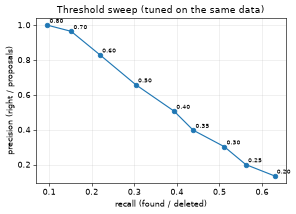

In [ ]:
low = datacopilot(
    "propose", "holdout.dcp", "--proposer", "grounding_dino", "--min-score", "0.2", timed=True
)
low_id = re.search(r"set=([0-9a-f]{32})", low.stdout).group(1)
low_set = dc.ProposalSet.model_validate_json(
    Path(f"holdout.dcp/proposals/{low_id}.json").read_text()
)
print()
curve = []
print(f"{'threshold':>9}{'proposals':>11}{'precision':>11}{'recall':>8}   (TUNED ON THE SAME DATA)")
for t in (0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6, 0.7, 0.8):
    kept = [p for p in low_set.proposals if p.score >= t]
    pr, rc, _ = precision_recall(kept)
    curve.append((t, pr, rc))
    print(f"{t:>9.2f}{len(kept):>11}{pr:>11.3f}{rc:>8.3f}")
at_default = sum(1 for p in low_set.proposals if p.score >= 0.35)
print(
    f"\nnote: the 0.35 row has {at_default} proposals, the default run {len(proposals.proposals)}: a lower --min-score also lowers the word threshold that names a box, so the two runs are close but not identical"
)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot([c[2] for c in curve], [c[1] for c in curve], "o-")
for t, pr, rc in curve:
    ax.annotate(f"{t:.2f}", (rc, pr), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("recall (found / deleted)")
ax.set_ylabel("precision (right / proposals)")
ax.set_title("Threshold sweep (tuned on the same data)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What this shows.** A higher threshold keeps fewer proposals that are more often right, at the price of finding fewer of the deleted boxes. The curve is labelled as tuned on the same data on purpose.

## 12. Six mistakes, drawn

The most confident wrong proposals, one per photo. **Green** = boxes the dataset has, **blue dashed** = boxes we deleted (the answer key), **red** = the wrong proposal. A red box on an object nobody labelled may be a correct find that the answer key simply lacks.

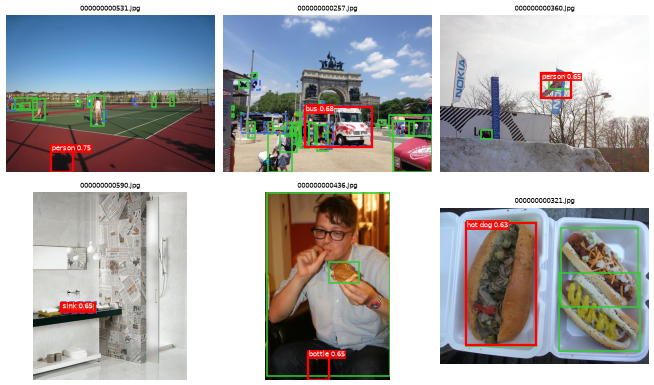

000000000531.jpg    proposed 'person' with confidence 0.75
000000000257.jpg    proposed 'bus' with confidence 0.68
000000000360.jpg    proposed 'person' with confidence 0.65
000000000590.jpg    proposed 'sink' with confidence 0.65
000000000436.jpg    proposed 'bottle' with confidence 0.65
000000000321.jpg    proposed 'hot dog' with confidence 0.63


In [ ]:
wrong = sorted(
    (p for p in proposals.proposals if p.proposal_id not in matches), key=lambda p: -p.score
)
chosen, seen_images = [], set()
for p in wrong:
    if p.image_id not in seen_images:
        seen_images.add(p.image_id)
        chosen.append(p)
    if len(chosen) == 6:
        break
kept_by_image = {}
for a in holdout.annotations:
    kept_by_image.setdefault(a.image_id, []).append(a)
path_of = {i.image_id: i.file_path for i in holdout.images}
fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
for ax, p in zip(axes.flat, chosen, strict=False):
    ax.imshow(PILImage.open(path_of[p.image_id]))
    for a in kept_by_image.get(p.image_id, []):
        x1, y1, x2, y2 = a.bbox_xyxy_abs
        ax.add_patch(
            plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="limegreen", linewidth=2
            )
        )
    for (image_id, _cls), boxes in held_by.items():
        if image_id == p.image_id:
            for x1, y1, x2, y2 in boxes:
                ax.add_patch(
                    plt.Rectangle(
                        (x1, y1),
                        x2 - x1,
                        y2 - y1,
                        fill=False,
                        edgecolor="royalblue",
                        linewidth=2,
                        linestyle="--",
                    )
                )
    x1, y1, x2, y2 = p.bbox_xyxy_abs
    ax.add_patch(
        plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=3)
    )
    ax.text(
        x1 + 3,
        y1 + 14,
        f"{class_name[p.category_id]} {p.score:.2f}",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="red", alpha=0.85, pad=1, edgecolor="none"),
    )
    ax.set_title(file_of[p.image_id], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
for p in chosen:
    print(
        f"{file_of[p.image_id]:<19} proposed '{class_name[p.category_id]}' with confidence {p.score:.2f}"
    )

**What this shows.** Six of the model's most confident mistakes. We did not check them all: look at each picture yourself. A box on an object nobody labelled may be a good find; a box on the wrong thing is a plain mistake. A human reviewer decides, which is why proposals are never applied on their own.

What kinds of mistakes are there overall? We sort every wrong proposal by what is near it, using the dataset's boxes and the deleted ones.

In [ ]:
def kind_of(p):
    box = np.array([p.bbox_xyxy_abs])
    truth = [(a.category_id, a.bbox_xyxy_abs) for a in kept_by_image.get(p.image_id, [])]
    truth += [(cls, b) for (iid, cls), bs in held_by.items() if iid == p.image_id for b in bs]
    same = [b for c, b in truth if c == p.category_id]
    other = [b for c, b in truth if c != p.category_id]
    if other and iou_xyxy(box, np.array(other)).max() >= 0.5:
        return "right place, but another class is labelled there"
    if same and iou_xyxy(box, np.array(same)).max() >= 0.1:
        return "overlaps a box of the same class (partly fits or duplicate)"
    return "nothing labelled nearby (unlabelled object or invented)"


kinds = Counter(kind_of(p) for p in wrong)
for kind, n in kinds.most_common():
    print(f"{n:>5}  {kind}")
print(f"{len(wrong):>5}  wrong proposals in all")

   88  nothing labelled nearby (unlabelled object or invented)
   34  overlaps a box of the same class (partly fits or duplicate)
    9  right place, but another class is labelled there
  131  wrong proposals in all


**What this shows.** How the wrong proposals divide up. The last group cannot be told apart here: it may mix real but never-labelled objects with plain inventions, and nothing in this notebook checks which.

## 13. When things go wrong: eight checks

Each row runs a real command that must be refused (or, for the early-ending run, must exit 1 and keep its partial set). The table is built from the real exit codes and messages.

In [ ]:
rows = []


def dcp_files(root):
    return sorted(str(p.relative_to(root)) for p in Path(root).rglob("*") if p.is_file())


parent_files = dcp_files("holdout.dcp")


def case(title, expected, args, env=None, check=None):
    result = datacopilot(*args, env=env)
    ok = result.returncode == 1 and (check is None or check(result))
    rows.append(
        (
            title,
            expected,
            f"exit {result.returncode}"
            + (": " + result.messages[0][:70] if result.messages else ""),
            "ok" if ok else "MISMATCH",
        )
    )
    return result


# 1. a tampered proposal file
set_file = Path(f"holdout.dcp/proposals/{reviewed_id}.json")
original = set_file.read_bytes()
doc = json.loads(original)
doc["proposals"][0]["score"] = 0.99
set_file.write_text(json.dumps(doc))
case(
    "a proposal file was edited by hand",
    "exit 1, refused",
    ["apply", "holdout.dcp", "--proposals", reviewed_id, "-o", "t1.dcp"],
    check=lambda r: "invalid" in " ".join(r.messages),
)
set_file.write_bytes(original)
# 2. a set made for another dataset version
datacopilot("ingest", "coco128", "--format", "yolo", "-o", "other.dcp")
Path("other.dcp/proposals").mkdir()
shutil.copy(set_file, Path("other.dcp/proposals") / set_file.name)
case(
    "the set belongs to another dataset version",
    "exit 1, refused",
    ["apply", "other.dcp", "--proposals", reviewed_id, "-o", "t2.dcp"],
    check=lambda r: "another dataset version" in " ".join(r.messages),
)
# 3. a model whose licence is not allowed (refused before any model file is read)
case(
    "the model licence is not on the allow-list",
    "exit 1, refused before loading",
    ["propose", "holdout.dcp", "--proposer", "grounding_dino"],
    env={"DATACOPILOT_ALLOWED_LICENSES": "mit"},
    check=lambda r: "DATACOPILOT_ALLOWED_LICENSES" in " ".join(r.messages),
)
# 3b. a proposal run that nobody reviewed
case(
    "apply a set nobody reviewed",
    "exit 1, refused",
    ["apply", "holdout.dcp", "--proposals", set_id, "-o", "t3.dcp"],
    check=lambda r: "review import" in " ".join(r.messages),
)
# 4. apply into the source directory
case(
    "apply writes into the source dataset",
    "exit 1, refused",
    ["apply", "holdout.dcp", "--proposals", reviewed_id, "-o", "holdout.dcp/inner.dcp"],
    check=lambda r: "outside the source" in " ".join(r.messages),
)
# 5. a hostile decision file
shutil.copytree("review", "review_hostile")
for path in Path("review_hostile").rglob("*.xml"):
    path.write_text(
        '<?xml version="1.0"?><!DOCTYPE a [<!ENTITY x "boom">]><annotations>&x;</annotations>'
    )
case(
    "the decision file contains an XML entity bomb",
    "exit 1, refused",
    ["review", "import", "holdout.dcp", "review_hostile", "--proposals", set_id, "--from", "cvat"],
    check=lambda r: "DOCTYPE" in " ".join(r.messages),
)
# 6. an incomplete run
short = datacopilot(
    "propose",
    "holdout.dcp",
    "--proposer",
    "grounding_dino",
    "--time-budget",
    "1",
    "--min-score",
    "0.2",
)
short_id = re.search(r"set=([0-9a-f]{32})", short.stdout).group(1)
rows.append(
    (
        "the run ended early (time budget)",
        "exit 1, partial set kept",
        f"exit {short.returncode}: " + (short.messages[-1][:60] if short.messages else ""),
        "ok" if short.returncode == 1 else "MISMATCH",
    )
)
short_set = dc.ProposalSet.model_validate_json(
    Path(f"holdout.dcp/proposals/{short_id}.json").read_text()
)
accepted_partial = short_set.derive(
    [p.model_copy(update={"status": "accepted"}) for p in short_set.proposals]
)
Path(f"holdout.dcp/proposals/{accepted_partial.set_id}.json").write_text(
    accepted_partial.model_dump_json() + "\n"
)
case(
    "apply an incomplete set without --allow-incomplete",
    "exit 1, refused",
    ["apply", "holdout.dcp", "--proposals", accepted_partial.set_id, "-o", "t6.dcp"],
    check=lambda r: "incomplete" in " ".join(r.messages),
)
print()
print(
    "source dataset files unchanged by all of this (except new set files):",
    [f for f in parent_files if f not in dcp_files("holdout.dcp")] == [],
)
print(
    "nothing was written by a refused command:",
    not any(
        Path(n).exists() for n in ("t1.dcp", "t2.dcp", "t3.dcp", "t6.dcp", "holdout.dcp/inner.dcp")
    ),
)

$ datacopilot apply holdout.dcp --proposals d83342ddb693f08424a059ee25a93bee -o t1.dcp
[message] error: proposal set d83342ddb693f08424a059ee25a93bee is invalid: ValidationError
[exit code 1]


$ datacopilot ingest coco128 --format yolo -o other.dcp
d9105ffb854e7dbeccf255a4848bd692
[exit code 0]


$ datacopilot apply other.dcp --proposals d83342ddb693f08424a059ee25a93bee -o t2.dcp
[message] error: the proposal set was made for another dataset version (92573e6e3c31e6a9b80a399411e90826); this one is d9105ffb854e7dbeccf255a4848bd692: propose again on this version
[exit code 1]


$ datacopilot propose holdout.dcp --proposer grounding_dino
[message] error: model 'grounding_dino' is licensed 'Apache-2.0', which is not in DATACOPILOT_ALLOWED_LICENSES; add it there if you have accepted its terms
[exit code 1]


$ datacopilot apply holdout.dcp --proposals e791c89da3c32c1b260cb7dd8fb5bed7 -o t3.dcp
[message] error: the proposal set has not been through `review import`: review it first (a fresh proposal run is never applied)
[exit code 1]


$ datacopilot apply holdout.dcp --proposals d83342ddb693f08424a059ee25a93bee -o holdout.dcp/inner.dcp
[message] error: the output must be a new directory outside the source dataset
[exit code 1]


$ datacopilot review import holdout.dcp review_hostile --proposals e791c89da3c32c1b260cb7dd8fb5bed7 --from cvat
[message] error: train.xml: DOCTYPE and entity declarations are not allowed in dataset XML
[exit code 1]


$ datacopilot propose holdout.dcp --proposer grounding_dino --time-budget 1 --min-score 0.2
proposed=14 images=1/128 set=27aad992d21491117947a0a403946d61 model=grounding_dino@a2bb814dd30d run_id=ad98ed38-e22f-4b6d-afc0-4403b0584ac8
[message] error: the run is incomplete (time_budget: 1 of 128 images); `apply` needs --allow-incomplete for this set
[exit code 1]


$ datacopilot apply holdout.dcp --proposals c1f412af0f2f0596a359f8eb339b0314 -o t6.dcp
[message] error: the proposal set is incomplete (time_budget: 1 of 128 images); applying it needs allow_incomplete
[exit code 1]

source dataset files unchanged by all of this (except new set files): True
nothing was written by a refused command: True


**What this shows.** Every dangerous request was refused with exit code 1 and a plain message, and nothing was written. The table follows.

In [ ]:
from IPython.display import Markdown, display

table = "| Case | Expected | Actual | |\n|---|---|---|---|\n" + "\n".join(
    f"| {a} | {b} | {c.replace('|', '/')} | {d} |" for a, b, c, d in rows
)
display(Markdown(table))
print(
    f"{len(rows)} cases, {sum(r[3] == 'ok' for r in rows)} as expected, {sum(r[3] != 'ok' for r in rows)} mismatches"
)

| Case | Expected | Actual | |
|---|---|---|---|
| a proposal file was edited by hand | exit 1, refused | exit 1: error: proposal set d83342ddb693f08424a059ee25a93bee is invalid: Valid | ok |
| the set belongs to another dataset version | exit 1, refused | exit 1: error: the proposal set was made for another dataset version (92573e6e | ok |
| the model licence is not on the allow-list | exit 1, refused before loading | exit 1: error: model 'grounding_dino' is licensed 'Apache-2.0', which is not i | ok |
| apply a set nobody reviewed | exit 1, refused | exit 1: error: the proposal set has not been through `review import`: review i | ok |
| apply writes into the source dataset | exit 1, refused | exit 1: error: the output must be a new directory outside the source dataset | ok |
| the decision file contains an XML entity bomb | exit 1, refused | exit 1: error: train.xml: DOCTYPE and entity declarations are not allowed in d | ok |
| the run ended early (time budget) | exit 1, partial set kept | exit 1: error: the run is incomplete (time_budget: 1 of 128 images); | ok |
| apply an incomplete set without --allow-incomplete | exit 1, refused | exit 1: error: the proposal set is incomplete (time_budget: 1 of 128 images);  | ok |

8 cases, 8 as expected, 0 mismatches


**What this shows.** Eight checks, all as expected, with the real message from each.

In [ ]:
p35, r35, right35 = precision, recall, n_right
best = max(curve, key=lambda c: 2 * c[1] * c[2] / (c[1] + c[2]) if c[1] + c[2] else 0)
verdict = "poor" if precision < 0.5 else "moderate" if precision < 0.75 else "good"
summary = f"""
| What we measured | Result |
|---|---|
| Boxes in the complete dataset | {len(full.annotations)} |
| Boxes deleted as the answer key | {len(held)} ({100 * len(held) / len(full.annotations):.1f} percent) |
| Proposals at the default threshold 0.35 | {len(proposals.proposals)} |
| Proposals that matched a deleted box (IoU 0.5, same class) | {right35} |
| Precision (an unlabelled find counts as wrong) | {p35:.3f} |
| Recall (oracle reviewer, random deletion) | {r35:.3f} |
| Tuned sweep, best balance (threshold {best[0]:.2f}, tuned on the same data) | precision {best[1]:.3f}, recall {best[2]:.3f} |
| Audit findings: complete / with holes / after applying matches | {sum(audit_full.values())} / {sum(audit_hole.values())} / {sum(audit_after.values())} |
| Boxes: complete / with holes / applied | {coverage_rows["complete"][0]} / {coverage_rows["with holes (held out)"][0]} / {coverage_rows["applied (matches only)"][0]} |
| Classes with a box in the validation split: complete / holes / applied | {coverage_rows["complete"][2]} / {coverage_rows["with holes (held out)"][2]} / {coverage_rows["applied (matches only)"][2]} |
| Run time of the model on this machine | {RUN_SECONDS:.0f} s for {proposals.images_total} photos |

**Verdict: the precision is {verdict}.** At the default threshold {100 * p35:.0f} percent of the proposals match a deleted box and {100 * r35:.0f} percent of the deleted boxes were found.
The measured precision counts a correct but never-labelled object as wrong, so it can understate the model; this notebook did not check by how much. The reviewer here is an oracle and the deletions are random, so recall is optimistic for real omissions. A person must review every proposal anyway: that is the design.
"""
display(Markdown(summary))


| What we measured | Result |
|---|---|
| Boxes in the complete dataset | 929 |
| Boxes deleted as the answer key | 178 (19.2 percent) |
| Proposals at the default threshold 0.35 | 215 |
| Proposals that matched a deleted box (IoU 0.5, same class) | 84 |
| Precision (an unlabelled find counts as wrong) | 0.391 |
| Recall (oracle reviewer, random deletion) | 0.472 |
| Tuned sweep, best balance (threshold 0.40, tuned on the same data) | precision 0.507, recall 0.393 |
| Audit findings: complete / with holes / after applying matches | 13 / 10 / 10 |
| Boxes: complete / with holes / applied | 929 / 751 / 835 |
| Classes with a box in the validation split: complete / holes / applied | 30 / 27 / 29 |
| Run time of the model on this machine | 254 s for 128 photos |

**Verdict: the precision is poor.** At the default threshold 39 percent of the proposals match a deleted box and 47 percent of the deleted boxes were found.
The measured precision counts a correct but never-labelled object as wrong, so it can understate the model; this notebook did not check by how much. The reviewer here is an oracle and the deletions are random, so recall is optimistic for real omissions. A person must review every proposal anyway: that is the design.


**What this shows.** The headline numbers of this run, computed above, with an honest verdict. The model is a helper that finds candidates for a person to check, not a labelling machine.

## 14. What you learned

| Step | What you did | Take-away |
|---|---|---|
| Pin | Checked the model licence, revision and checksums | A model is only loaded after its licence is allowed and every file matches a checksum written in advance. |
| Hold out | Deleted a seeded 20 percent of the boxes | An answer key lets you measure a model instead of trusting it. |
| Propose | Ran the real Grounding DINO model | Suggestions are stored as a proposal set bound to the dataset version; nothing is changed. |
| Review | Exported to CVAT files and imported decisions | A reviewer decides; deleting a box decides nothing; a hostile file is refused as a whole. |
| Apply | Wrote a new dataset version | The old version is untouched and the new one names its parent. |
| Sweep | Looked at other thresholds | Tuned on the same data, so optimistic; the default was fixed in advance. |
| Refusals | Eight dangerous requests | Tampered, mismatched, unlicensed, in-place, hostile and incomplete cases all stop with exit code 1. |